# 1A: Sunburst

In [ ]:
# Cohort Stats
#Population Group	Discovery Cohort	Validation Cohort	Replication Cohort
#AFR	129	1297	163
#AMR	327	290	67
#EAS	18	123	95
#EUR	55	296	72
#SAS	10	78	103
#MID	4	18	0
#Total	543	2102	500
#Technology	HiFi	HiFi	ONT
#Median Depth	32	12	35


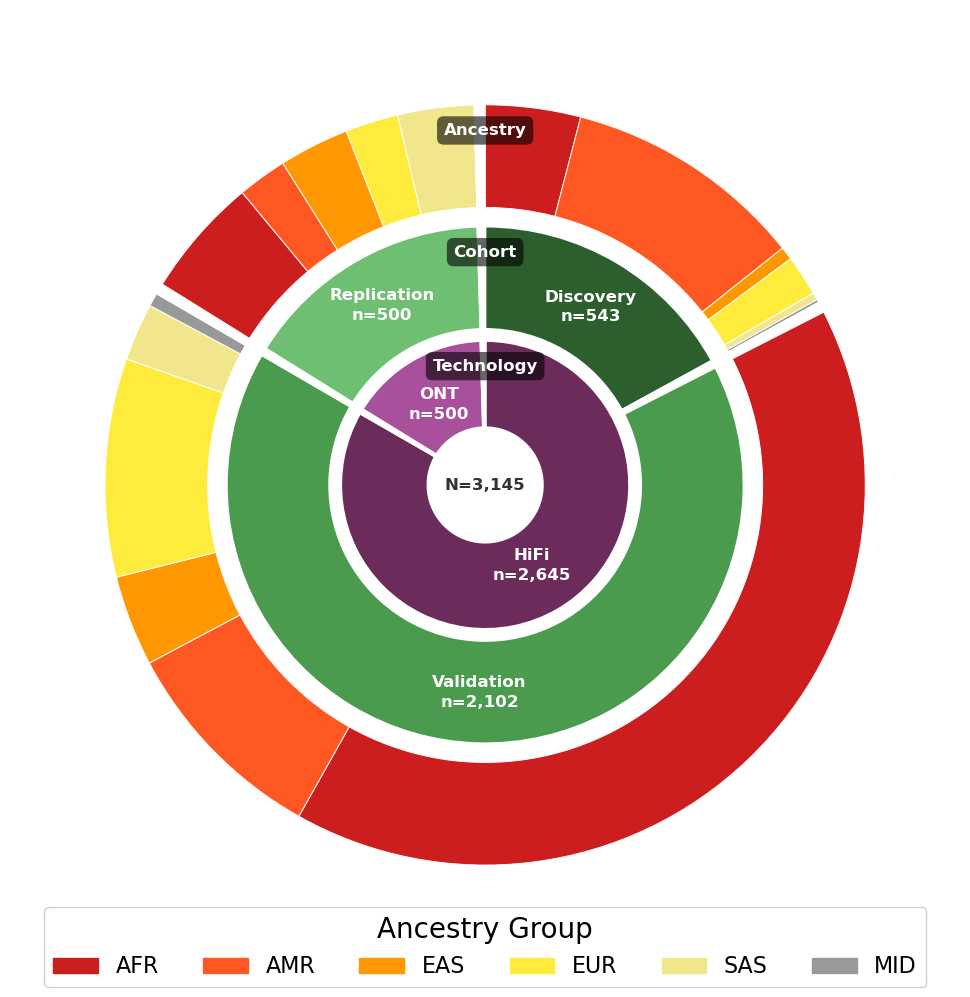

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ─── Data ────────────────────────────────────────────────────────────────────
ancestries   = ['AFR', 'AMR', 'EAS', 'EUR', 'SAS', 'MID']
cohort_order = ['Discovery', 'Validation', 'Replication']

cohort_data = {
    'Discovery':   {'Technology': 'HiFi', 'AFR': 129,  'AMR': 327, 'EAS': 18,
                                           'EUR': 55,   'SAS': 10,  'MID': 4},
    'Validation':  {'Technology': 'HiFi', 'AFR': 1297, 'AMR': 290, 'EAS': 123,
                                           'EUR': 296,  'SAS': 78,  'MID': 18},
    'Replication': {'Technology': 'ONT',  'AFR': 163,  'AMR': 67,  'EAS': 95,
                                           'EUR': 72,   'SAS': 103, 'MID': 0},
}

# ─── Colors ──────────────────────────────────────────────────────────────────
# Inner ring (Technology): shades of blue
tech_colors   = {'HiFi': '#6B2C5B', 'ONT': '#A8509C'}
# Middle ring (Cohort): shades of green
cohort_colors = {'Discovery': '#2D5F2E', 'Validation': '#4A9B4D', 'Replication': '#6FBF73'}
# Outer ring (Ancestry): 
colorPalette=['#CC1E1E','#FF5722','#FF9800','#FFEB3B','#F0E68C']

anc_colors    = {
    'AFR': '#CC1E1E', 'AMR': '#FF5722', 'EAS': '#FF9800',
    'EUR': '#FFEB3B', 'SAS': '#F0E68C', 'MID': '0.6',
}

# ─── Build ring data with spacers ────────────────────────────────────────────
# Inner: Technology  (HiFi = Discovery + Validation,  ONT = Replication)
tech_map   = [('HiFi', ['Discovery', 'Validation']), ('ONT', ['Replication'])]
tech_sizes_base = [sum(cohort_data[c][a] for c in cs for a in ancestries) for _, cs in tech_map]
tech_names = [t for t, _ in tech_map]

# Add spacers between technologies
gap_size = 15  # size of gap wedges
tech_sizes = []
tech_clrs = []
for i, (name, size) in enumerate(zip(tech_names, tech_sizes_base)):
    tech_sizes.append(size)
    tech_clrs.append(tech_colors[name])
    tech_sizes.append(gap_size)  # add spacer
    tech_clrs.append('white')

# Middle: Cohort with spacers
cohort_sizes_base = [sum(cohort_data[c][a] for a in ancestries) for c in cohort_order]
cohort_sizes = []
cohort_clrs = []
for i, (name, size) in enumerate(zip(cohort_order, cohort_sizes_base)):
    cohort_sizes.append(size)
    cohort_clrs.append(cohort_colors[name])
    cohort_sizes.append(gap_size)  # add spacer
    cohort_clrs.append('white')

# Outer: Ancestry within each cohort with spacers at cohort boundaries
outer_sizes = []
outer_clrs = []
for i, c in enumerate(cohort_order):
    for j, a in enumerate(ancestries):
        outer_sizes.append(cohort_data[c][a])
        outer_clrs.append(anc_colors[a])
    outer_sizes.append(gap_size)  # add spacer after each cohort
    outer_clrs.append('white')

# ─── Plot geometry ───────────────────────────────────────────────────────────
W  = 0.27   # ring width
R3 = 1.00   # ancestry  (outer)
R2 = 0.68   # cohort    (middle) - adjust for spacing
R1 = 0.38   # technology (inner) - adjust for spacing
SA = 90     # start angle (top of chart)

fig, ax = plt.subplots(figsize=(13, 10))
ax.set_aspect('equal')
ax.axis('off')

kw = lambda lw: dict(width=W, edgecolor='white', linewidth=lw)
ax.pie(outer_sizes,  radius=R3, colors=outer_clrs,  startangle=SA, counterclock=False, wedgeprops=kw(0.7))
ax.pie(cohort_sizes, radius=R2, colors=cohort_clrs, startangle=SA, counterclock=False, wedgeprops=kw(1.5))
ax.pie(tech_sizes,   radius=R1, colors=tech_clrs,   startangle=SA, counterclock=False, wedgeprops=dict(width=W*0.85, edgecolor='white', linewidth=2.0))

# ─── Manual labels at radial midpoint of each ring ───────────────────────────
def ring_label_xy(values, idx, r, start_deg=SA):
    """Return (x, y) at arc midpoint of wedge `idx` for a CW pie (counterclock=False)."""
    total_v = sum(values)
    midfrac = (sum(values[:idx]) + values[idx] / 2) / total_v
    angle   = np.radians(start_deg - 360 * midfrac)   # CW = decreasing angle
    return r * np.cos(angle), r * np.sin(angle)

# Label technologies (skip spacers - every other wedge)
for i, (name, size) in enumerate(zip(tech_names, tech_sizes_base)):
    wedge_idx = i * 2  # account for spacers
    x, y = ring_label_xy(tech_sizes, wedge_idx, R1 - W / 2)
    ax.text(x, y, f'{name}\nn={size:,}', ha='center', va='center',
            fontsize=12, fontweight='bold', color='white', linespacing=1.4)

# Label cohorts (skip spacers - every other wedge)
for i, (cohort, size) in enumerate(zip(cohort_order, cohort_sizes_base)):
    wedge_idx = i * 2  # account for spacers
    x, y = ring_label_xy(cohort_sizes, wedge_idx, R2 - W / 2)
    ax.text(x, y, f'{cohort}\nn={size:,}', ha='center', va='center',
            fontsize=12, fontweight='bold', color='white', linespacing=1.4)

# Center: grand total
ax.text(0, 0, f'N={sum(tech_sizes_base):,}', ha='center', va='center',
        fontsize=12, fontweight='bold', color='#333333')

# ─── Ring labels at 12 o'clock (no arrows) ──────────────────────────────────
# Place labels at 90° (top) at the radial midpoint of each ring
ax.text(0, R1 - W/4, 'Technology', ha='center', va='center',
        fontsize=12, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='black', alpha=0.6, edgecolor='none'))

ax.text(0, R2 - W/4, 'Cohort', ha='center', va='center',
        fontsize=12, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='black', alpha=0.6, edgecolor='none'))

ax.text(0, R3 - W/4, 'Ancestry', ha='center', va='center',
        fontsize=12, fontweight='bold', color='white',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='black', alpha=0.6, edgecolor='none'))

# ─── Ancestry legend ─────────────────────────────────────────────────────────
handles = [mpatches.Patch(color=anc_colors[a], label=a) for a in ancestries]
ax.legend(handles=handles, title='Ancestry Group', title_fontsize=20,
          loc='lower center', bbox_to_anchor=(0.5, -0.04),
          ncol=6, fontsize=16, framealpha=0.9)

plt.tight_layout()
plt.savefig('figures/Figure1A.svg', bbox_inches='tight')
plt.savefig('figures/Figure1A.png', bbox_inches='tight', dpi=600)
plt.show()

# 1B: Cohort Consistency

In [ ]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

highCovComplete=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lowCovComplete=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
AFR=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_alleleLengthStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
ONT=pd.read_csv('statsTables/ReplicationCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')



In [25]:
# Calculate correlations between each dataset and highCovComplete for all percentile columns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from scipy.stats import pearsonr
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Get all percentile column names
percentile_cols = [col for col in highCovComplete.columns if 'Percentile' in col]

# Define datasets for comparison
datasets = {
    'Validation Cohort': lowCovComplete,
    'AFR-only': AFR,
    'AMR-only': AMR,
    'EAS-only': EAS,
    'EUR-only': EUR,
    'SAS-only': SAS,
    'Replication Cohort': ONT
}

# Calculate correlations for each dataset and percentile column
correlation_results = []

for dataset_name, dataset in datasets.items():
    # Merge with highCovComplete on TRID
    merged = pd.merge(
        highCovComplete[['TRID'] + percentile_cols], 
        dataset[['TRID'] + percentile_cols], 
        on='TRID', 
        suffixes=('_ref', '_test')
    )
    
    # Calculate correlation for each percentile column
    for col in percentile_cols:
        ref_col = f'{col}_ref'
        test_col = f'{col}_test'
        
        # Remove any rows with NaN values
        valid_data = merged[[ref_col, test_col]].dropna()
        
        if len(valid_data) > 0:
            # Calculate Pearson correlation
            pearson_r, pearson_p = pearsonr(valid_data[ref_col], valid_data[test_col])
            
            correlation_results.append({
                'Dataset': dataset_name,
                'Percentile': col,
                'Pearson_r': pearson_r,
                'n_loci': len(valid_data)
            })


C:\Users\Matt\AppData\Local\Temp\ipykernel_78560\2736742397.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


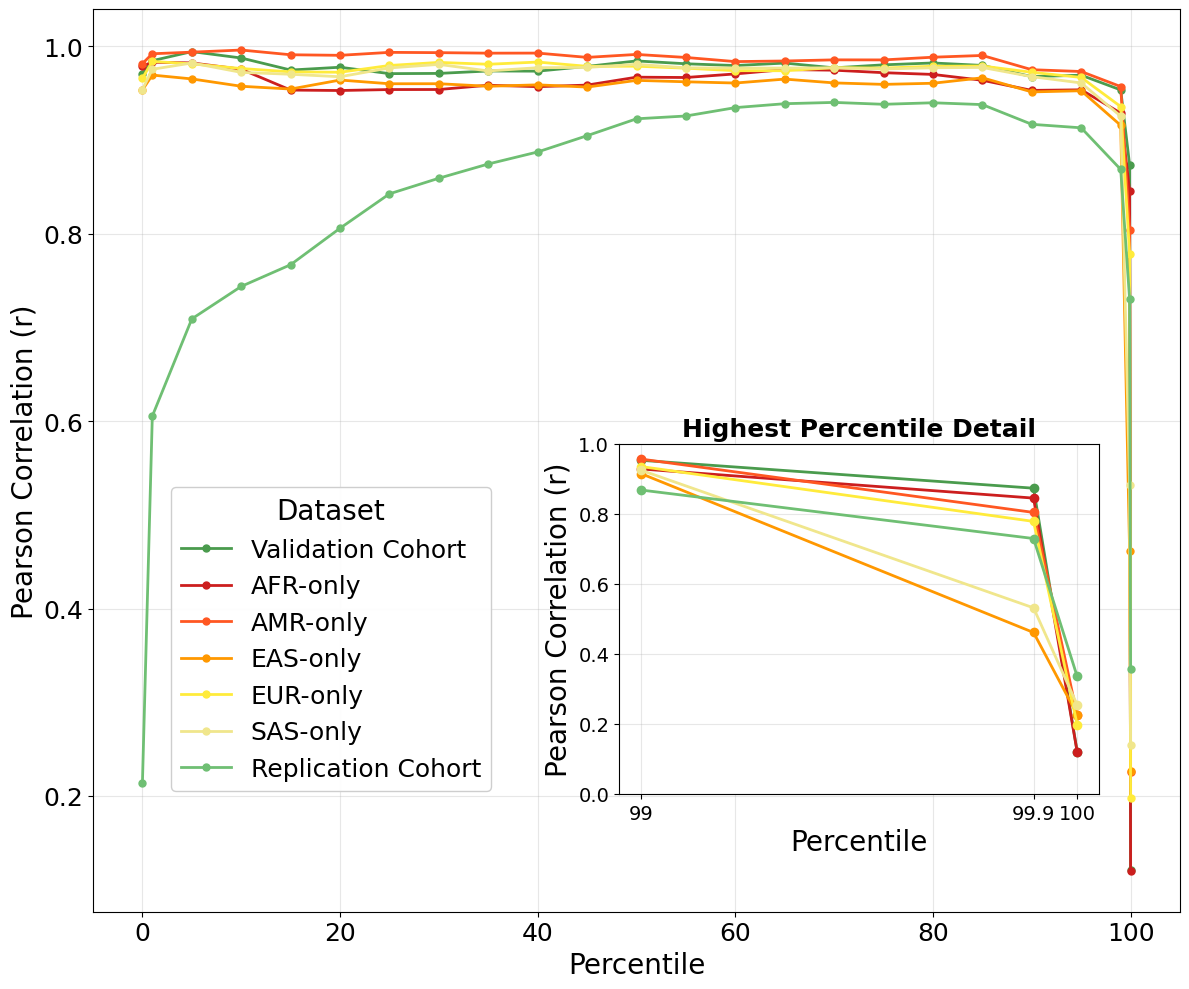


=== Correlation Summary Statistics ===

Mean Pearson Correlation by Dataset:
                     mean    min    max
Dataset                                
AFR-only            0.924  0.120  0.983
AMR-only            0.947  0.225  0.996
EAS-only            0.907  0.227  0.969
EUR-only            0.934  0.198  0.984
Replication Cohort  0.811  0.214  0.940
SAS-only            0.924  0.255  0.982
Validation Cohort   0.937  0.121  0.994

Correlation at key percentiles:

90th Percentile:
           Dataset  Pearson_r
 Validation Cohort   0.967635
          AFR-only   0.952969
          AMR-only   0.975044
          EAS-only   0.951339
          EUR-only   0.972275
          SAS-only   0.967626
Replication Cohort   0.916759

95th Percentile:
           Dataset  Pearson_r
 Validation Cohort   0.969184
          AFR-only   0.953585
          AMR-only   0.973120
          EAS-only   0.952580
          EUR-only   0.966810
          SAS-only   0.960908
Replication Cohort   0.913020

99th Percent

In [ ]:
# plot results
# Convert to DataFrame
corr_df = pd.DataFrame(correlation_results)

# Extract numeric percentile value for plotting
corr_df['Percentile_Value'] = corr_df['Percentile'].str.replace('Percentile', '').str.replace('st', '').str.replace('nd', '').str.replace('rd', '').str.replace('th','').astype(float)

# Create visualization with inset
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

fig, ax1 = plt.subplots(1, 1, figsize=(12, 10))

# Get colors matching the existing plot style
dataset_colors={
    'Validation Cohort': '#4A9B4D',
    'AFR-only': '#CC1E1E',
    'AMR-only': '#FF5722',
    'EAS-only': '#FF9800',
    'EUR-only': '#FFEB3B',
    'SAS-only': '#F0E68C',
    'Replication Cohort': '#6FBF73'}

# Plot Pearson correlations on main panel
for idx, dataset_name in enumerate(datasets.keys()):
    data_subset = corr_df[corr_df['Dataset'] == dataset_name].sort_values('Percentile_Value')
    ax1.plot(data_subset['Percentile_Value'], data_subset['Pearson_r'],
             marker='o', label=dataset_name, color=dataset_colors[dataset_name], linewidth=2, markersize=5)

ax1.set_xlabel('Percentile', fontsize=20)
ax1.set_ylabel('Pearson Correlation (r)', fontsize=20)
ax1.tick_params(labelsize=18)
#ax1.set_title('Allele Length Percentile Correlation vs High Coverage Reference', fontsize=14, fontweight='bold')
ax1.grid(axis='both', alpha=0.3)

# Position legend in bottom left with padding
ax1.legend(title='Dataset', loc='lower left', bbox_to_anchor=(0.06, 0.12), fontsize=18, framealpha=0.95,title_fontsize=20)

# Create inset axes in bottom right with padding
# bbox_to_anchor: (x, y, width, height) in axes coordinates
ax_inset = fig.add_axes([0.52, 0.2, 0.4, 0.35])

# Plot only 99th, 99.9th, and 100th percentiles on inset
extreme_percentiles = [99, 99.9, 100]
for idx, dataset_name in enumerate(datasets.keys()):
    data_subset = corr_df[corr_df['Dataset'] == dataset_name].sort_values('Percentile_Value')
    data_extreme = data_subset[data_subset['Percentile_Value'].isin(extreme_percentiles)]
    ax_inset.plot(data_extreme['Percentile_Value'], data_extreme['Pearson_r'],
                  marker='o', color=dataset_colors[dataset_name], linewidth=2, markersize=6)

ax_inset.set_xlabel('Percentile', fontsize=20)
ax_inset.set_ylabel('Pearson Correlation (r)', fontsize=20)
ax_inset.set_title('Highest Percentile Detail', fontsize=18, fontweight='bold')
ax_inset.set_xticks([99, 99.9, 100])
ax_inset.set_xticklabels(['99', '99.9', '100'])
ax_inset.grid(axis='both', alpha=0.3)
ax_inset.set_ylim([0.0, 1.0])
ax_inset.tick_params(labelsize=14)

plt.tight_layout()
plt.savefig('figures/Figure1B.svg')
plt.savefig('figures/Figure1B.png',dpi=600)
plt.show()

# Print summary statistics
print("\n=== Correlation Summary Statistics ===")
print("\nMean Pearson Correlation by Dataset:")
print(corr_df.groupby('Dataset')['Pearson_r'].agg(['mean', 'min', 'max']).round(3))
print("\nCorrelation at key percentiles:")
for perc in [90, 95, 99, 99.9, 100]:
    print(f"\n{perc}th Percentile:")
    perc_data = corr_df[corr_df['Percentile_Value'] == perc][['Dataset', 'Pearson_r']]
    if not perc_data.empty:
        print(perc_data.to_string(index=False))

# 1C: Discovery Curve

In [ ]:
import polars as pl
import numpy as np
import glob
import pandas as pd


def simulate_chromosome_discoveries(parquet_file, MAX_OBSERVATIONS):
    print(f"Running simulation on {parquet_file}...")
    
    # Load the frequency lists for this chromosome
    df = pl.read_parquet(parquet_file)
    freq_lists = df["FrequencyList"].to_list()
    
    # Array to tally discoveries at each observation step (0 to 2171)
    chrom_discoveries = np.zeros(MAX_OBSERVATIONS, dtype=int)
    
    for freq_list in freq_lists:
        # Skip empty lists (loci with no successful observations)
        if not freq_list:
            continue
            
        # 1. Create a simulated pool of alleles for this locus
        # E.g., if freq_list is [1082, 1, 1], allele_pool becomes [0,0,...,0, 1, 2]
        allele_pool = np.repeat(np.arange(len(freq_list)), freq_list)
        
        # 2. Shuffle the pool to simulate randomly observing people one by one
        np.random.shuffle(allele_pool)
        
        # 3. Find the step (index) where each unique allele first appears
        _, first_discovery_steps = np.unique(allele_pool, return_index=True)
        
        # 4. Tally these discoveries into our chromosome-wide tracker
        # We use bincount to count how many alleles were discovered at step 0, 1, etc.
        locus_tally = np.bincount(first_discovery_steps, minlength=MAX_OBSERVATIONS)
        chrom_discoveries += locus_tally
        
    return chrom_discoveries

In [ ]:
# Discovery Cohort
MAX_OBSERVATIONS = 1086 
parquet_files = glob.glob("assets/saturationCurves/chr*_allele_frequencies_over25x.parquet")
total_new_discoveries_per_step = np.zeros(MAX_OBSERVATIONS, dtype=int)
for p_file in parquet_files:
    chrom_tally = simulate_chromosome_discoveries(p_file, MAX_OBSERVATIONS)
    total_new_discoveries_per_step += chrom_tally
discoveryCohort = total_new_discoveries_per_step.cumsum()

# Validation Cohort
MAX_OBSERVATIONS = 4258 
parquet_files = glob.glob("assets/saturationCurves/chr*_allele_frequencies_under25x.parquet")
total_new_discoveries_per_step = np.zeros(MAX_OBSERVATIONS, dtype=int)
for p_file in parquet_files:
    chrom_tally = simulate_chromosome_discoveries(p_file, MAX_OBSERVATIONS)
    total_new_discoveries_per_step += chrom_tally
validationCohort = total_new_discoveries_per_step.cumsum()

# Replication Cohort
MAX_OBSERVATIONS = 1000 
parquet_files = glob.glob("assets/saturationCurves/chr*_allele_frequencies_ONT.parquet")
total_new_discoveries_per_step = np.zeros(MAX_OBSERVATIONS, dtype=int)
for p_file in parquet_files:
    chrom_tally = simulate_chromosome_discoveries(p_file, MAX_OBSERVATIONS)
    total_new_discoveries_per_step += chrom_tally
replicationCohort = total_new_discoveries_per_step.cumsum()

# save to file
np.save('assets/saturationCurves/discoveryCohort_alleleSeqObservations.npy',discoveryCohort)
np.save('assets/saturationCurves/validationCohort_alleleSeqObservations.npy',validationCohort)
np.save('assets/saturationCurves/replicationCohort_alleleSeqObservations.npy',replicationCohort)


In [ ]:
# Discovery Cohort
MAX_OBSERVATIONS = 1086 
parquet_files = glob.glob("assets/saturationCurves/chr*_allele_length_frequencies_over25x.parquet")
total_new_discoveries_per_step = np.zeros(MAX_OBSERVATIONS, dtype=int)
for p_file in parquet_files:
    chrom_tally = simulate_chromosome_discoveries(p_file, MAX_OBSERVATIONS)
    total_new_discoveries_per_step += chrom_tally
discoveryCohort = total_new_discoveries_per_step.cumsum()

# Validation Cohort
MAX_OBSERVATIONS = 4258 
parquet_files = glob.glob("assets/saturationCurves/chr*_allele_length_frequencies_under25x.parquet")
total_new_discoveries_per_step = np.zeros(MAX_OBSERVATIONS, dtype=int)
for p_file in parquet_files:
    chrom_tally = simulate_chromosome_discoveries(p_file, MAX_OBSERVATIONS)
    total_new_discoveries_per_step += chrom_tally
validationCohort = total_new_discoveries_per_step.cumsum()

# Replication Cohort
MAX_OBSERVATIONS = 1000 
parquet_files = glob.glob("assets/saturationCurves/chr*_allele_length_frequencies_ONT.parquet")
total_new_discoveries_per_step = np.zeros(MAX_OBSERVATIONS, dtype=int)
for p_file in parquet_files:
    chrom_tally = simulate_chromosome_discoveries(p_file, MAX_OBSERVATIONS)
    total_new_discoveries_per_step += chrom_tally
replicationCohort = total_new_discoveries_per_step.cumsum()

# save to file
np.save('assets/saturationCurves/discoveryCohort_alleleLengthObservations.npy',discoveryCohort)
np.save('assets/saturationCurves/validationCohort_alleleLengthObservations.npy',validationCohort)
np.save('assets/saturationCurves/replicationCohort_alleleLengthObservations.npy',replicationCohort)


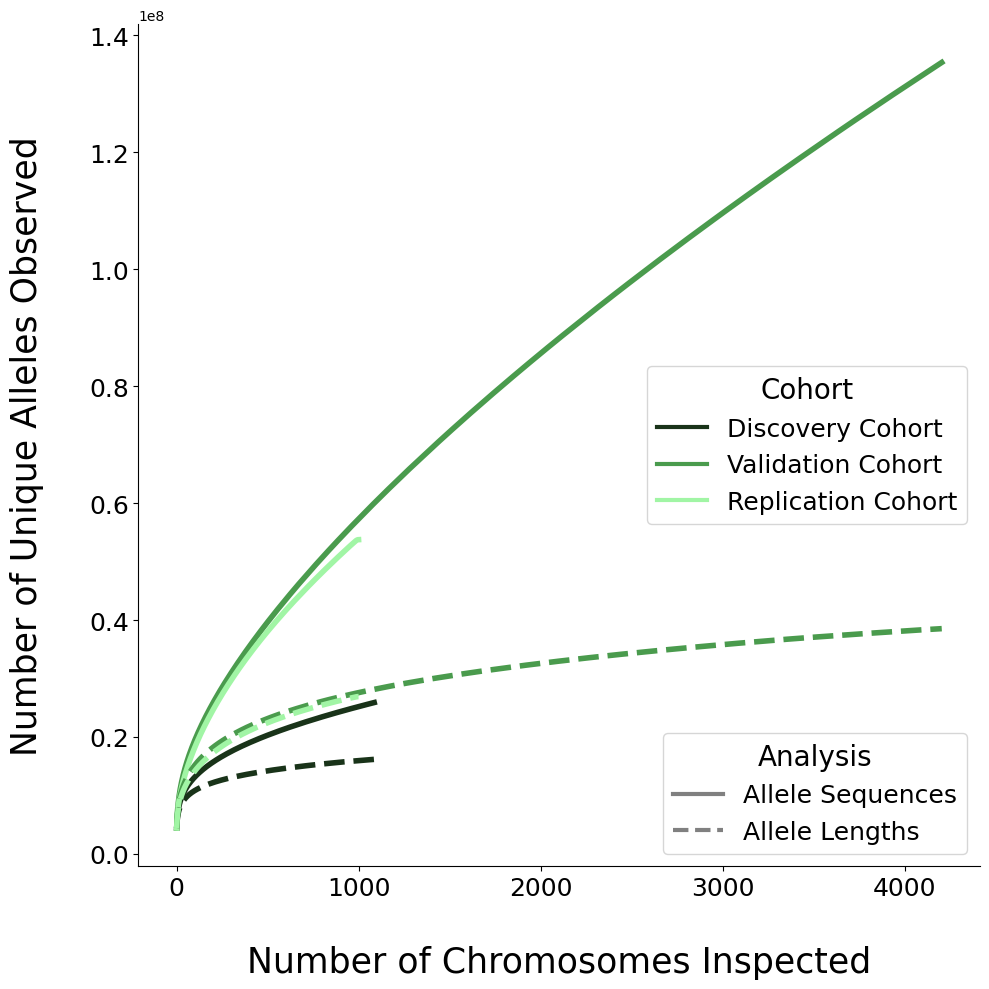

In [ ]:
# plot the saturation curve
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

discoveryCohort=np.load('assets/saturationCurves/discoveryCohort_alleleSeqObservations.npy')
validationCohort=np.load('assets/saturationCurves/validationCohort_alleleSeqObservations.npy')
replicationCohort=np.load('assets/saturationCurves/replicationCohort_alleleSeqObservations.npy')
validationCohort=validationCohort[:4203]

discoveryCohort2=np.load('assets/saturationCurves/discoveryCohort_alleleLengthObservations.npy')
validationCohort2=np.load('assets/saturationCurves/validationCohort_alleleLengthObservations.npy')
replicationCohort2=np.load('assets/saturationCurves/replicationCohort_alleleLengthObservations.npy')
validationCohort2=validationCohort2[:4203]


cohort_colors = {'Discovery': "#193319", 'Validation': '#4A9B4D', 'Replication': "#A1F5A5"}

fig, ax = plt.subplots(figsize=(10, 10))
plt.plot(discoveryCohort,c=cohort_colors['Discovery'], linewidth=4)
plt.plot(validationCohort,c=cohort_colors['Validation'], linewidth=4)
plt.plot(replicationCohort,c=cohort_colors['Replication'], linewidth=4)
plt.plot(discoveryCohort2,c=cohort_colors['Discovery'], linewidth=4, linestyle='--')
plt.plot(validationCohort2,c=cohort_colors['Validation'], linewidth=4, linestyle='--')
plt.plot(replicationCohort2,c=cohort_colors['Replication'], linewidth=4, linestyle='--')
plt.ylabel('Number of Unique Alleles Observed\n',fontsize=25)
plt.xlabel('\nNumber of Chromosomes Inspected',fontsize=25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Legend 1: cohort colors
cohort_handles = [
    Line2D([0], [0], color=cohort_colors['Discovery'], linewidth=3, label='Discovery Cohort'),
    Line2D([0], [0], color=cohort_colors['Validation'], linewidth=3, label='Validation Cohort'),
    Line2D([0], [0], color=cohort_colors['Replication'], linewidth=3, label='Replication Cohort'),
]
legend1 = ax.legend(handles=cohort_handles, title='Cohort', loc='center right', fontsize=18, title_fontsize=20)
ax.add_artist(legend1)  # keep legend1 when legend2 is added

# Legend 2: line styles (analysis type)
style_handles = [
    Line2D([0], [0], color='gray', linewidth=3, linestyle='-', label='Allele Sequences'),
    Line2D([0], [0], color='gray', linewidth=3, linestyle='--', label='Allele Lengths'),
]
ax.legend(handles=style_handles, title='Analysis', loc='lower right', fontsize=18, title_fontsize=20)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.tight_layout()
plt.savefig('figures/Figure1C.svg')
plt.savefig('figures/Figure1C.png',dpi=600)

# 1D: Allele Sizes Per Person

In [ ]:
# The following code was run on RWB to generate the input data for Figure 1D, which is used in the final block to make the plot

In [ ]:
%%writefile polars_allele_size_bins.py
import polars as pl
import sys

# ============================================================================
# Configuration
# Pass chromosome as a command-line argument, e.g.: python polars_allele_size_bins.py "under25x" "22"
# ============================================================================
COHORT = sys.argv[1] if len(sys.argv) > 1 else "."
CHROM = sys.argv[2] if len(sys.argv) > 2 else "22"

INPUT_FILE  = f'{COHORT}/alleleInfo_chr{CHROM}_trgt.TR_Explorer_1.0.1.txt.gz'
OUTPUT_FILE = f'{COHORT}_allele_size_bins_chr{CHROM}.txt'

BIN_NAMES = [
    'under50bp',
    '50-99bp',
    '100-149bp',
    '150-199bp',
    '200-299bp',
    '300-399bp',
    '400-499bp',
    'over500bp',
]

print(f"Processing chromosome {CHROM}")
print(f"Input:  {INPUT_FILE}")
print(f"Output: {OUTPUT_FILE}")

# ============================================================================
# Build per-allele bin indicator expressions
# length_col: the integer column to bin (a1_len or a2_len)
# prefix:     column name prefix for output ('a1' or 'a2')
# '.' values were converted to null above, so they contribute 0 to all bins
# ============================================================================
def bin_exprs(length_col: str, prefix: str) -> list:
    c = pl.col(length_col)
    return [
        pl.when(c < 50)                    .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_under50bp'),
        pl.when((c >= 50)  & (c < 100))   .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_50-99bp'),
        pl.when((c >= 100) & (c < 150))   .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_100-149bp'),
        pl.when((c >= 150) & (c < 200))   .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_150-199bp'),
        pl.when((c >= 200) & (c < 300))   .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_200-299bp'),
        pl.when((c >= 300) & (c < 400))   .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_300-399bp'),
        pl.when((c >= 400) & (c < 500))   .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_400-499bp'),
        pl.when(c >= 500)                  .then(1).otherwise(0).cast(pl.Int32).alias(f'{prefix}_over500bp'),
    ]

# ============================================================================
# Process: scan -> parse lengths -> bin -> combine alleles -> aggregate
# ============================================================================
result = (
    pl.scan_csv(
        INPUT_FILE,
        separator='\t',
        has_header=True,
        infer_schema_length=0,   # read everything as strings first
    )
    # Parse Allele1_Len and Allele2_Len: '.' -> null (won't count in any bin)
    .with_columns([
        pl.when(pl.col('Allele1_Len') == '.')
          .then(None)
          .otherwise(pl.col('Allele1_Len').str.to_integer(strict=False))
          .alias('a1_len'),

        pl.when(pl.col('Allele2_Len') == '.')
          .then(None)
          .otherwise(pl.col('Allele2_Len').str.to_integer(strict=False))
          .alias('a2_len'),
    ])
    # Create a 0/1 indicator for each bin, for each allele
    .with_columns(bin_exprs('a1_len', 'a1') + bin_exprs('a2_len', 'a2'))
    # Sum the two alleles into a single count per bin
    .with_columns([
        (pl.col(f'a1_{b}') + pl.col(f'a2_{b}')).alias(b)
        for b in BIN_NAMES
    ])
    .select(['SampleID'] + BIN_NAMES)
    # Aggregate: one row per participant
    .group_by('SampleID')
    .agg([pl.col(b).sum() for b in BIN_NAMES])
    .collect(engine='streaming')
)

# Sort by SampleID for reproducibility
result = result.sort('SampleID')

print(f"\nChr {CHROM}: processed {len(result):,} participants")
print("\nSummary (allele counts per bin, summed across all participants):")
for b in BIN_NAMES:
    print(f"  {b:12s}: {result[b].sum():>12,}")

# ============================================================================
# Save output
# ============================================================================
result.write_csv(OUTPUT_FILE,separator='\t')
print(f"\nSaved: {OUTPUT_FILE}")



In [ ]:
%%bash
# download the alleleInfo tables
mkdir -p over25x
mkdir -p under25x
gcloud storage cp gs://fc-secure-a3225c5b-3828-4657-8a82-98874f6652a8/alleleInfo_v8/over25x/alleleInfo_chr*_trgt.TR_Explorer_1.0.1.txt.gz ./over25x/
gcloud storage cp gs://fc-secure-a3225c5b-3828-4657-8a82-98874f6652a8/alleleInfo_v8/under25x/alleleInfo_chr*_trgt.TR_Explorer_1.0.1.txt.gz ./under25x/

for CHROM in {1..22} "X" "Y"; do
python polars_allele_size_bins.py 'over25x' ${CHROM}
python polars_allele_size_bins.py 'under25x' ${CHROM}
done

In [ ]:
# repeat for replication cohort
%%bash
mkdir ONT
cd ONT/
aws s3 cp s3://zuchnerlab/1000Genomes/ONT/medaka_TRExplorer_v1.0.1/ . --recursive --exclude "*" --include "*_LPS.txt.gz"
echo -e "SampleID\tTRID\tAllele1\tAllele2\tAllele1_LPS_Length\tAllele1_LPS_Motif\tAllele2_LPS_Length\tAllele2_LPS_Motif\tAllele1_Len\tAllele2_Len\tAllele1_DP\tAllele2_DP" > header.txt
for chrom in "1" "2" "3" "4" "5" "6" "7" "8" "9" "10" "11" "12" "13" "14" "15" "16" "17" "18" "19" "20" "21" "22" "X" "Y"; do
zcat *chr${chrom}_LPS.txt.gz | cat header.txt - | gzip -c > "alleleInfo_chr${chrom}_medaka.TR_Explorer_1.0.1.txt.gz"
python polars_allele_size_bins.py ${chrom}
done


In [ ]:
# merge output results by sampleID across chromosomes
import polars as pl, glob
BIN_NAMES = [
    'under50bp',
    '50-99bp',
    '100-149bp',
    '150-199bp',
    '200-299bp',
    '300-399bp',
    '400-499bp',
    'over500bp',
]

combined = (
    pl.concat([pl.read_csv(f, separator='\t') for f in glob.glob("over25x_allele_size_bins_chr*.txt")])
    .group_by('SampleID')
    .agg([pl.col(b).sum() for b in BIN_NAMES])
)
combined.write_csv("assets/discoveryCohort_allele_size_bins.txt", separator='\t')
combined = (
    pl.concat([pl.read_csv(f, separator='\t') for f in glob.glob("under25x_allele_size_bins_chr*.txt")])
    .group_by('SampleID')
    .agg([pl.col(b).sum() for b in BIN_NAMES])
)
combined.write_csv("assets/validationCohort_allele_size_bins.txt", separator='\t')
combined = (
    pl.concat([pl.read_csv(f, separator='\t') for f in glob.glob("ONT_allele_size_bins_chr*.txt")])
    .group_by('SampleID')
    .agg([pl.col(b).sum() for b in BIN_NAMES])
)
combined.write_csv("assets/replicationCohort_allele_size_bins.txt", separator='\t')


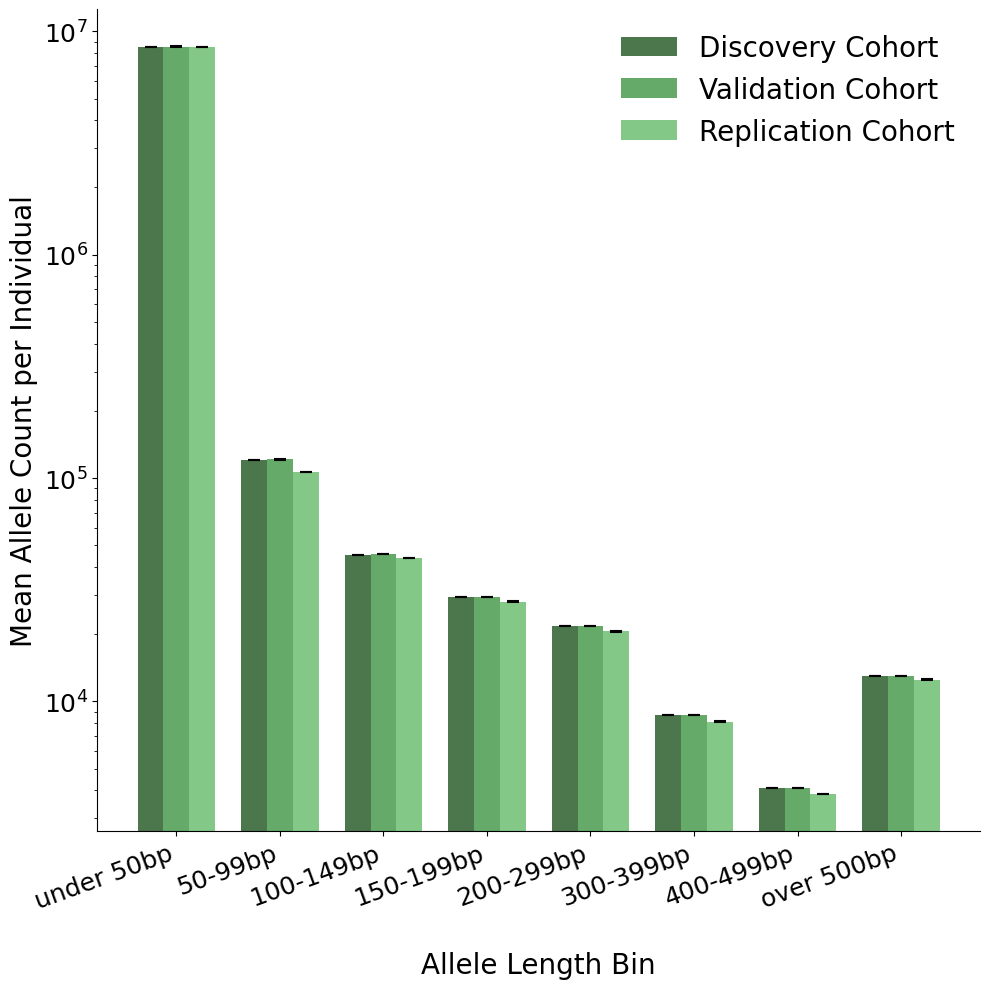

In [ ]:
# Plot Figure 1D
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

BIN_NAMES = ['under50bp', '50-99bp', '100-149bp', '150-199bp',
             '200-299bp', '300-399bp', '400-499bp', 'over500bp']
BIN_NAME_LABELS = ['under 50bp', '50-99bp', '100-149bp', '150-199bp',
             '200-299bp', '300-399bp', '400-499bp', 'over 500bp']

cohort_colors = ['#2D5F2E', '#4A9B4D', '#6FBF73']
cohort_labels = ['Discovery Cohort', 'Validation Cohort', 'Replication Cohort']
cohort_files  = ['assets/discoveryCohort_allele_size_bins.txt', 'assets/validationCohort_allele_size_bins.txt', 'assets/replicationCohort_allele_size_bins.txt']

# Load data and compute mean ± SEM per bin across individuals
cohort_means, cohort_sems = [], []
for f in cohort_files:
    df = pd.read_csv(f, sep='\t', index_col='SampleID')
    cohort_means.append(df[BIN_NAMES].mean())
    cohort_sems.append(df[BIN_NAMES].sem())

# ── Plot ──────────────────────────────────────────────────────────────────────
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

n_bins  = len(BIN_NAMES)
x       = np.arange(n_bins)
width   = 0.25
offsets = np.array([-width, 0.0, width])

fig, ax = plt.subplots(figsize=(10, 10))

for i in range(3):
    ax.bar(
        x + offsets[i],
        cohort_means[i],
        width=width,
        color=cohort_colors[i],
        alpha=0.85,
        label=cohort_labels[i],
        yerr=cohort_sems[i],
        capsize=4,
        error_kw=dict(ecolor='black', linewidth=1.5, capthick=1.5),
    )

ax.set_xticks(x)
ax.set_xticklabels(BIN_NAME_LABELS, fontsize=18, rotation=20, ha='right')
ax.set_xlabel('\nAllele Length Bin', fontsize=20)
ax.set_ylabel('Mean Allele Count per Individual', fontsize=20)
ax.tick_params(axis='y', labelsize=18)
plt.yscale('log')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=20, frameon=False)

plt.tight_layout()
plt.savefig('figures/Figure1D.png',dpi=600)
plt.savefig('figures/Figure1D.svg')
